# Classificação da Localização Celular de Proteínas de Levedura (*Yeast*)
**Disciplina:** Aprendizado de Máquina (2025.2) — Centro de Informática (CIn / UFPE)  
**Professor:** Francisco de A. T. de Carvalho  

**Equipe:**
* Andreywid Yago Lima de Souza
* Artur Vinícius Pereira Fernandes
* Heitor Higino Holanda Cordeiro
* Arthur Thierre Dos Santos Silva

---

## 1. Contextualização e Metadados da Base de Dados

A base de dados **Yeast**, criada por Kenta Nakai (Universidade de Osaka) e doada por Paul Horton ao repositório *UCI Machine Learning Repository* ([UCI Dataset #110](https://archive.ics.uci.edu/dataset/110/yeast)), reúne **1.484 proteínas** de levedura (*Saccharomyces cerevisiae*), descritas por **8 atributos preditivos numéricos** derivados de análises bioquímicas e reconhecimento de sequências de aminoácidos.

O objetivo consiste em resolver um problema de **classificação supervisionada multiclasse fortemente desbalanceada**, prevendo o sítio de localização subcelular (`class_protein`) entre **10 classes possíveis**.

### Dicionário de Atributos Preditivos
| Atributo | Tipo | Descrição Bioquímica / Computacional |
| :--- | :--- | :--- |
| `mcg` | Contínuo | Método de McGeoch para reconhecimento de sequência sinal |
| `gvh` | Contínuo | Método de von Heijne para reconhecimento de sequência sinal |
| `alm` | Contínuo | Pontuação do programa ALOM para predição de região transmembranar |
| `mit` | Contínuo | Análise discriminante do conteúdo de aminoácidos N-terminal (20 resíduos) de proteínas mitocondriais |
| `erl` | Binário (`0.5` / `1.0`) | Presença da subsequência `"HDEL"` (sinal de retenção no lúmen do retículo endoplasmático) |
| `pox` | Contínuo (esparso) | Sinal de direcionamento peroxissomal na extremidade C-terminal |
| `vac` | Contínuo | Análise discriminante do conteúdo de aminoácidos de proteínas vacuolares e extracelulares |
| `nuc` | Contínuo | Análise discriminante de sinais de localização nuclear |

### Classes de Localização Celular (`class_protein`)
* `CYT` — Citosólica ou citoesquelética (463 amostras)
* `NUC` — Nuclear (429 amostras)
* `MIT` — Mitocondrial (244 amostras)
* `ME3` — Proteína de membrana sem sinal N-terminal (163 amostras)
* `ME2` — Proteína de membrana com sinal não clivado (51 amostras)
* `ME1` — Proteína de membrana com sinal clivado (44 amostras)
* `EXC` — Extracelular (35 amostras)
* `VAC` — Vacuolar (30 amostras)
* `POX` — Peroxissomal (20 amostras)
* `ERL` — Lúmen do retículo endoplasmático (5 amostras)

## 2. Importação de Bibliotecas e Carregamento Portátil da Base
O carregamento abaixo funciona de forma **totalmente reprodutível e portátil**, localizando automaticamente `data/yeast.data` ou `data/yeast-datasets.zip` (seja em execução local via Jupyter ou no Google Colab), sem depender de caminhos fixos.

In [1]:
import io
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
RANDOM_STATE = 42

COLUMN_NAMES = [
    "sequence_name", "mcg", "gvh", "alm", "mit",
    "erl", "pox", "vac", "nuc", "class_protein",
]
FEATURE_COLUMNS = COLUMN_NAMES[1:-1]


def load_yeast_dataset() -> pd.DataFrame:
    """Localiza e carrega a base Yeast automaticamente (arquivo local, ZIP ou Colab)."""
    search_paths = [
        Path("../data/yeast.data"),
        Path("data/yeast.data"),
        Path("yeast.data"),
        Path("/content/drive/MyDrive/Projeto_AM/Datasets/yeast.data"),
    ]
    for p in search_paths:
        if p.is_file():
            return pd.read_csv(p, sep=r"\s+", header=None, names=COLUMN_NAMES)

    for zp in [Path("../data/yeast-datasets.zip"), Path("data/yeast-datasets.zip")]:
        if zp.is_file():
            with zipfile.ZipFile(zp, "r") as zf:
                member = next(m for m in zf.namelist() if m.endswith("yeast.data"))
                return pd.read_csv(
                    io.BytesIO(zf.read(member)),
                    sep=r"\s+",
                    header=None,
                    names=COLUMN_NAMES,
                )

    raise FileNotFoundError("Arquivo 'yeast.data' não encontrado em '../data/' ou 'data/'.")


df_raw = load_yeast_dataset()
# Remove o identificador textual SWISS-PROT (não preditivo)
df_yeast = df_raw.drop(columns=["sequence_name"]).copy()
print(f"Dimensões da base carregada: {df_yeast.shape[0]} amostras x {df_yeast.shape[1]} colunas")
df_yeast.head()

Dimensões da base carregada: 1484 amostras x 9 colunas


,mcg,gvh,alm,mit,erl,pox,vac,nuc,class_protein
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


### 2.1 Verificação de Tipos, Integridade e Estatísticas Descritivas

In [2]:
print("Valores ausentes por coluna:")
print(df_yeast.isna().sum())
print("\nResumo estatístico dos atributos preditivos:")
display(df_yeast[FEATURE_COLUMNS].describe().T.round(4))

Valores ausentes por coluna:
mcg              0
gvh              0
alm              0
mit              0
erl              0
pox              0
vac              0
nuc              0
class_protein    0
dtype: int64

Resumo estatístico dos atributos preditivos:


,count,mean,std,min,25%,50%,75%,max
mcg,1484.0,0.5001,0.1373,0.11,0.41,0.49,0.58,1.00
gvh,1484.0,0.4999,0.1239,0.13,0.42,0.49,0.57,1.00
alm,1484.0,0.5000,0.0867,0.21,0.46,0.51,0.55,1.00
mit,1484.0,0.2612,0.1371,0.00,0.17,0.22,0.32,1.00
erl,1484.0,0.5047,0.0484,0.50,0.50,0.50,0.50,1.00
pox,1484.0,0.0075,0.0757,0.00,0.00,0.00,0.00,0.83
vac,1484.0,0.4999,0.0578,0.00,0.48,0.51,0.53,0.73
nuc,1484.0,0.2762,0.1065,0.00,0.22,0.22,0.30,1.00


## 3. Análise Exploratória de Dados (EDA)

### 3.1 Distribuição da Variável-Alvo e Desbalanceamento de Classes
Antes da modelagem, avaliamos a distribuição das 10 classes de localização celular para dimensionar o grau de desbalanceamento do problema.

,Amostras,Proporção (%)
class_protein,,
CYT,463,31.20
NUC,429,28.91
MIT,244,16.44
ME3,163,10.98
ME2,51,3.44
ME1,44,2.96
EXC,35,2.36
VAC,30,2.02
POX,20,1.35


Razão de desbalanceamento máxima (CYT / ERL): 92.6:1


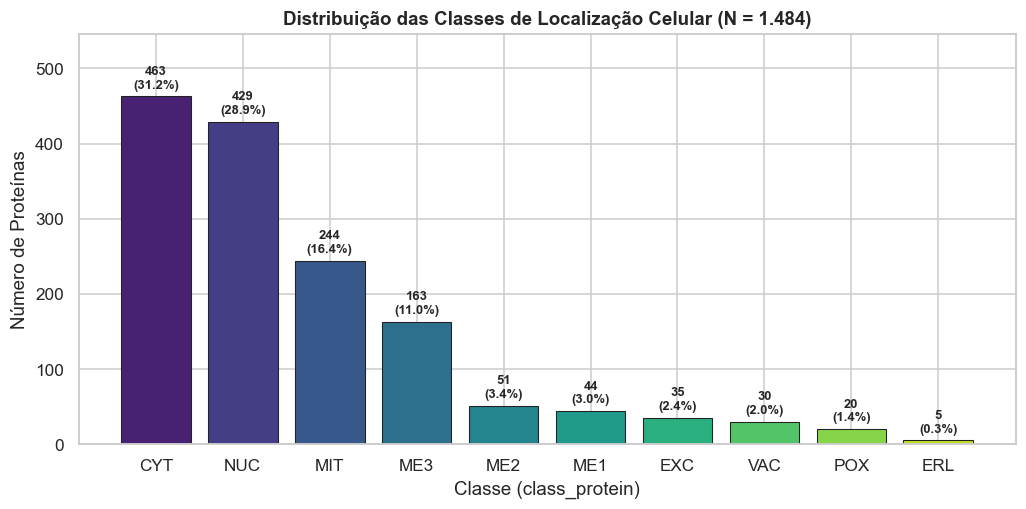

In [3]:
class_counts = df_yeast["class_protein"].value_counts()
class_pcts = (class_counts / len(df_yeast) * 100).round(2)
dist_summary = pd.DataFrame({"Amostras": class_counts, "Proporção (%)": class_pcts})
display(dist_summary)
print(f"Razão de desbalanceamento máxima (CYT / ERL): {class_counts.max() / class_counts.min():.1f}:1")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=sns.color_palette("viridis", len(class_counts)),
    edgecolor="#222222",
    linewidth=0.7,
)
for bar, cnt, pct in zip(bars, class_counts.values, class_pcts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 7,
        f"{cnt}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="semibold",
    )
ax.set_title("Distribuição das Classes de Localização Celular (N = 1.484)")
ax.set_xlabel("Classe (class_protein)")
ax.set_ylabel("Número de Proteínas")
ax.set_ylim(0, class_counts.max() * 1.18)
plt.tight_layout()
plt.show()

**Comentário:** As quatro classes majoritárias (`CYT`, `NUC`, `MIT` e `ME3`) concentram **87,5%** de toda a base (1.299 de 1.484 proteínas), enquanto classes minoritárias como `POX` (20 amostras; 1,35%) e `ERL` (apenas 5 amostras; 0,34%) possuem baixíssima representatividade. Consequentemente:
1. A simples acurácia global pode mascarar falhas severas nas classes minoritárias, tornando indispensável o acompanhamento de **Precision, Recall e F1-Score (Macro e Ponderado)**;
2. Toda divisão de dados deve obrigatoriamente utilizar **amostragem estratificada (`stratify=y`)**.

### 3.2 Análise Univariada dos Atributos Preditivos

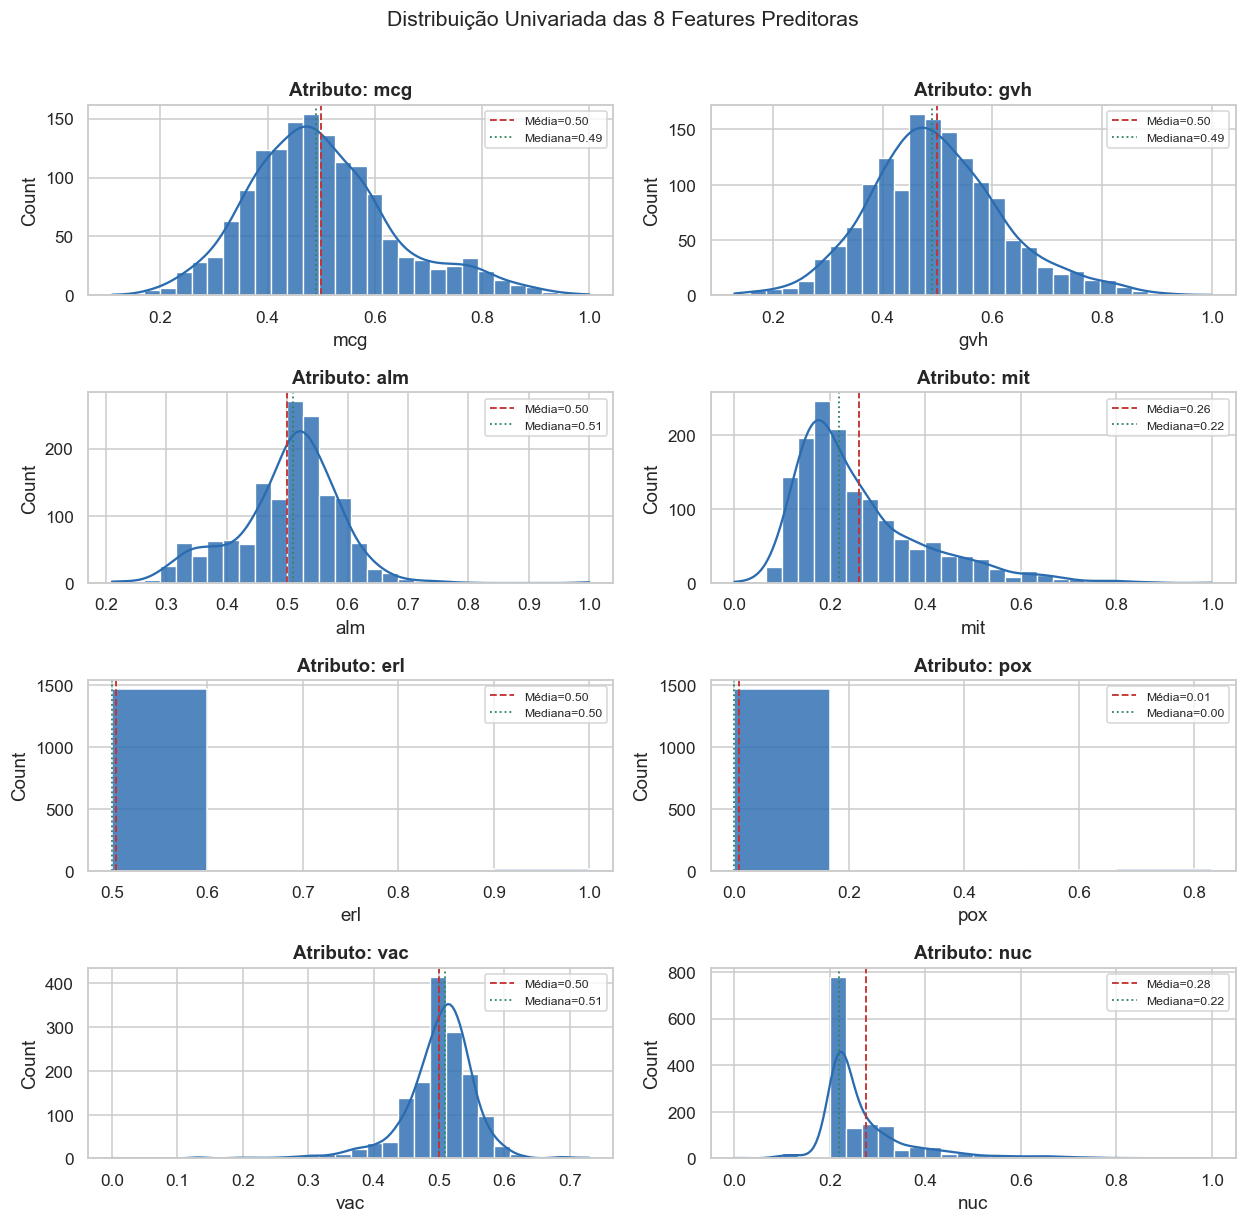

In [4]:
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(11.5, 11))
for idx, feat in enumerate(FEATURE_COLUMNS):
    ax = axes.flatten()[idx]
    n_unique = df_yeast[feat].nunique()
    sns.histplot(
        df_yeast[feat],
        bins=min(30, max(5, n_unique)),
        kde=(n_unique > 5),
        color="#2b6cb0",
        edgecolor="white",
        alpha=0.82,
        ax=ax,
    )
    ax.axvline(df_yeast[feat].mean(), color="#c53030", linestyle="--", linewidth=1.2, label=f"Média={df_yeast[feat].mean():.2f}")
    ax.axvline(df_yeast[feat].median(), color="#2f855a", linestyle=":", linewidth=1.2, label=f"Mediana={df_yeast[feat].median():.2f}")
    ax.set_title(f"Atributo: {feat}")
    ax.legend(fontsize=8)

fig.suptitle("Distribuição Univariada das 8 Features Preditoras", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Comentário:** Os atributos `mcg`, `gvh` e `vac` exibem distribuições contínuas unimodais próximas à simetria, enquanto `mit` e `nuc` apresentam assimetria positiva acentuada (cauda longa à direita). Destacam-se dois atributos fortemente degenerados/esparsos: `erl` assume exclusivamente dois valores (`0.5` em 99,06% dos casos e `1.0` em 0,94%) e `pox` é nulo na quase totalidade das amostras — característica que exige atenção especial na modelagem probabilística Gaussiana (*Naive Bayes*).

### 3.3 Análise Bivariada: Boxplots por Classe e Matriz de Correlação

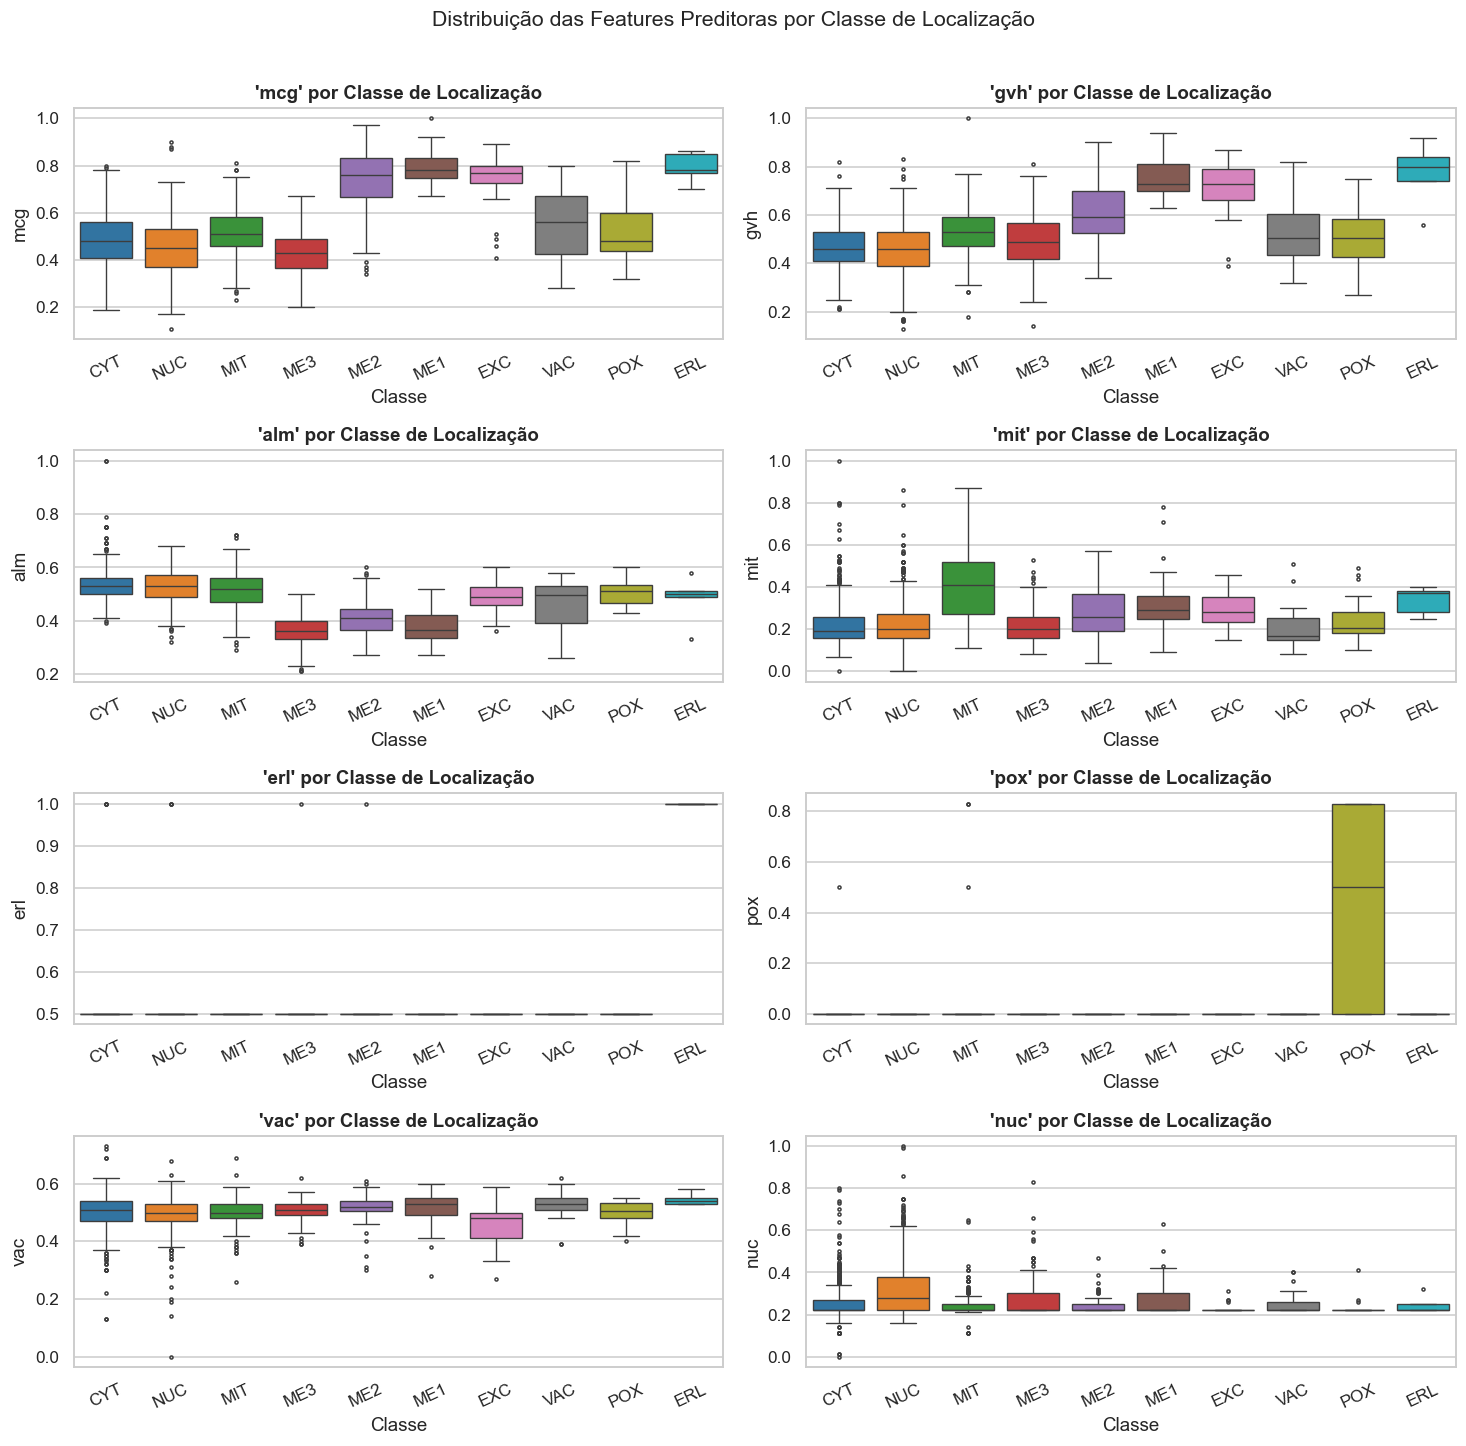

In [5]:
class_order = class_counts.index.tolist()
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(13.5, 13))
for idx, feat in enumerate(FEATURE_COLUMNS):
    ax = axes.flatten()[idx]
    sns.boxplot(
        data=df_yeast,
        x="class_protein",
        y=feat,
        order=class_order,
        hue="class_protein",
        hue_order=class_order,
        palette="tab10",
        legend=False,
        fliersize=2.0,
        linewidth=0.9,
        ax=ax,
    )
    ax.set_title(f"'{feat}' por Classe de Localização")
    ax.set_xlabel("Classe")
    ax.tick_params(axis="x", rotation=25)

fig.suptitle("Distribuição das Features Preditoras por Classe de Localização", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

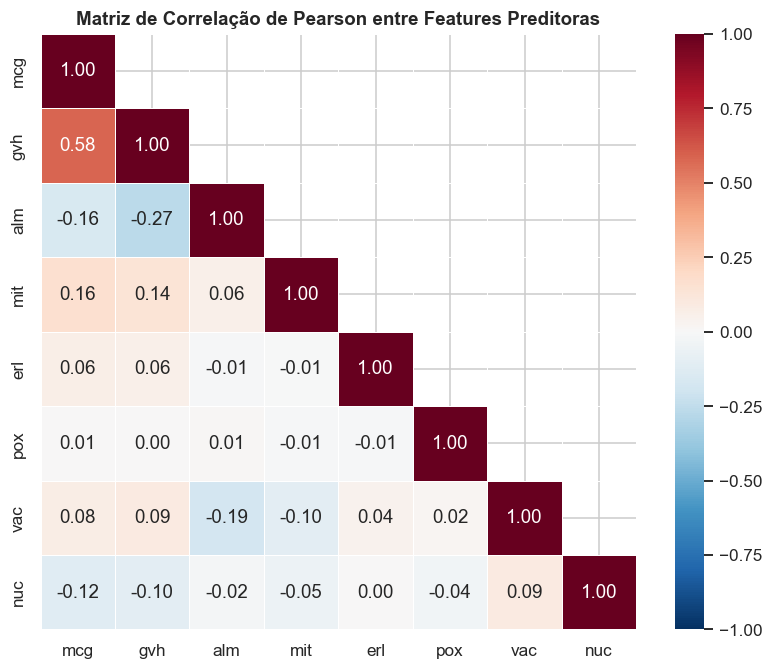

In [6]:
corr_matrix = df_yeast[FEATURE_COLUMNS].corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.6, 6.2))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1.0,
    vmax=1.0,
    center=0.0,
    square=True,
    linewidths=0.6,
    ax=ax,
)
ax.set_title("Matriz de Correlação de Pearson entre Features Preditoras")
plt.tight_layout()
plt.show()

**Comentário:**
* Os boxplots confirmam o poder discriminativo seletivo de diversos atributos: valores elevados de `mcg` e `gvh` distinguem `ME1`, `EXC` e `ERL`; valores baixos de `alm` caracterizam proteínas de membrana integral (`ME1`, `ME2`, `ME3`); `mit` destaca `MIT`; `pox` discrimina `POX`; e `erl = 1.0` sinaliza fortemente `ERL`. Entretanto, `CYT` e `NUC` exibem expressiva sobreposição em quase todos os atributos (diferenciando-se sutilmente em `nuc`), o que impõe um limite intrínseco Bayesiano de separabilidade entre essas duas classes majoritárias.
* A matriz de correlação evidencia **correlação positiva moderada ($r = 0,58$) entre `mcg` e `gvh`**, esperado biologicamente pois ambos quantificam sequências-sinal N-terminais. Essa dependência viola parcialmente a hipótese de independência condicional do classificador Bayesiano Ingênuo.

---

## 4. Pré-processamento e Divisão Estratificada Sem Vazamento de Dados

Seguindo rigorosamente as instruções do projeto:
1. **Codificação de rótulos (`LabelEncoder`)**: converte as 10 classes categóricas em inteiros `0..9`.
2. **Divisão aleatória e estratificada (70% Treinamento + Validação / 30% Teste)**: `X_test` (446 exemplos) permanece **estritamente isolado**, não participando nem da padronização nem da escolha de hiperparâmetros.
3. **Prevenção de *Data Leakage* na Validação Cruzada**: a padronização (`StandardScaler`) é encapsulada dentro de um `sklearn.pipeline.Pipeline` com o classificador. Assim, em cada dobra da validação cruzada, média e desvio-padrão são estimados exclusivamente sobre os dados de treino daquela dobra.
4. **Esquema de Validação Cruzada (`StratifiedKFold(n_splits=3)`)**: como a menor classe (`ERL`, 5 exemplos totais) possui exatamente **3 exemplos** no conjunto de treino (70%), o uso de $k = 3$ dobras estratificadas garante que **todas as 10 classes estejam presentes em 100% das dobras de validação**, evitando distorções na métrica `f1_macro`.

In [7]:
label_encoder = LabelEncoder()
X = df_yeast[FEATURE_COLUMNS].copy()
y = label_encoder.fit_transform(df_yeast["class_protein"])
target_names = label_encoder.classes_

class_mapping = {cls: int(idx) for cls, idx in zip(target_names, label_encoder.transform(target_names))}
print("Mapeamento de classes:", class_mapping)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

cv_splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

split_check = pd.DataFrame({
    "Classe": target_names,
    "Treino+Val (70%)": np.bincount(y_train),
    "Teste (30%)": np.bincount(y_test),
    "Total": np.bincount(y),
})
display(split_check)

Mapeamento de classes: {'CYT': 0, 'ERL': 1, 'EXC': 2, 'ME1': 3, 'ME2': 4, 'ME3': 5, 'MIT': 6, 'NUC': 7, 'POX': 8, 'VAC': 9}


,Classe,Treino+Val (70%),Teste (30%),Total
0,CYT,324,139,463
1,ERL,3,2,5
2,EXC,24,11,35
3,ME1,31,13,44
4,ME2,36,15,51
5,ME3,114,49,163
6,MIT,171,73,244
7,NUC,300,129,429
8,POX,14,6,20
9,VAC,21,9,30


In [8]:
def compute_metrics_dict(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_weighted": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


baseline_records = []
tuned_records = []
best_models = {}
test_predictions = {}

---

## 5. Treinamento, Otimização de Hiperparâmetros e Avaliação no Conjunto de Teste

Para cada um dos **5 classificadores exigidos**, comparamos o modelo **Baseline (configuração padrão)** com o modelo **Otimizado via `GridSearchCV`** (maximizando `f1_macro` exclusivamente por validação cruzada no conjunto de treino de 70%), avaliando ao final no conjunto de teste retido (30%).

### 5.1 Modelo 1 — Árvore de Decisão (`DecisionTreeClassifier`)

In [9]:
# Baseline
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)
y_pred_dt_base = dt_base.predict(X_test)
baseline_records.append({"Modelo": "Árvore de Decisão", "Etapa": "Baseline (Padrão)", **compute_metrics_dict(y_test, y_pred_dt_base)})

# Otimização via Pipeline + GridSearchCV
pipe_dt = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
param_grid_dt = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [None, 5, 7, 9, 12],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__ccp_alpha": [0.0, 0.003],
    "clf__class_weight": [None, "balanced"],
}

grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=cv_splitter, scoring="f1_macro", n_jobs=1)
grid_dt.fit(X_train, y_train)

best_models["DecisionTree"] = grid_dt.best_estimator_
y_pred_dt = grid_dt.predict(X_test)
test_predictions["DecisionTree"] = y_pred_dt
tuned_records.append({
    "Modelo": "Árvore de Decisão",
    "Etapa": "Otimizado (GridSearchCV)",
    "cv_f1_macro": grid_dt.best_score_,
    **compute_metrics_dict(y_test, y_pred_dt),
})

print("Melhores hiperparâmetros (Árvore de Decisão):", grid_dt.best_params_)
print(f"Melhor F1-Macro na Validação Cruzada: {grid_dt.best_score_:.4f}\n")
print("--- Relatório de Classificação no Teste (Árvore de Decisão Otimizada) ---")
print(classification_report(y_test, y_pred_dt, target_names=target_names, zero_division=0))

Melhores hiperparâmetros (Árvore de Decisão): {'clf__ccp_alpha': 0.0, 'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Melhor F1-Macro na Validação Cruzada: 0.4925

--- Relatório de Classificação no Teste (Árvore de Decisão Otimizada) ---
              precision    recall  f1-score   support

         CYT       0.49      0.53      0.51       139
         ERL       1.00      1.00      1.00         2
         EXC       0.43      0.55      0.48        11
         ME1       0.71      0.92      0.80        13
         ME2       0.31      0.33      0.32        15
         ME3       0.77      0.90      0.83        49
         MIT       0.49      0.53      0.51        73
         NUC       0.57      0.42      0.48       129
         POX       0.40      0.33      0.36         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.53       446
   macro avg       0

**Análise (Árvore de Decisão):** Sem poda e sem ponderação de classes, a árvore padrão sofre *overfitting* severo nas classes majoritárias (`F1-Macro = 0,40`, ignorando completamente `ERL` e `VAC`). Ao controlar `max_depth=5`, `criterion='entropy'` e `class_weight='balanced'`, o **F1-Macro no teste salta de 0,40 para 0,53** (+13 p.p.) e o Recall Macro sobe de 0,40 para 0,55, recuperando classes minoritárias como `ERL`, `EXC`, `ME1` e `POX`.

---

### 5.2 Modelo 2 — Bayesiano Ingênuo (`GaussianNB`)

In [10]:
# Baseline (var_smoothing padrão = 1e-9)
gnb_base = GaussianNB()
gnb_base.fit(X_train, y_train)
y_pred_gnb_base = gnb_base.predict(X_test)
baseline_records.append({"Modelo": "Bayesiano Ingênuo", "Etapa": "Baseline (Padrão)", **compute_metrics_dict(y_test, y_pred_gnb_base)})

print(f"Acurácia do GaussianNB Baseline (var_smoothing=1e-9): {accuracy_score(y_test, y_pred_gnb_base):.4f}")

# Otimização de var_smoothing via Pipeline + GridSearchCV
pipe_gnb = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", GaussianNB()),
])
param_grid_gnb = {
    "clf__var_smoothing": np.logspace(-9, 0.2, 40),
}

grid_gnb = GridSearchCV(pipe_gnb, param_grid_gnb, cv=cv_splitter, scoring="f1_macro", n_jobs=1)
grid_gnb.fit(X_train, y_train)

best_models["GaussianNB"] = grid_gnb.best_estimator_
y_pred_gnb = grid_gnb.predict(X_test)
test_predictions["GaussianNB"] = y_pred_gnb
tuned_records.append({
    "Modelo": "Bayesiano Ingênuo",
    "Etapa": "Otimizado (GridSearchCV)",
    "cv_f1_macro": grid_gnb.best_score_,
    **compute_metrics_dict(y_test, y_pred_gnb),
})

print("Melhor hiperparâmetro (GaussianNB):", grid_gnb.best_params_)
print(f"Melhor F1-Macro na Validação Cruzada: {grid_gnb.best_score_:.4f}\n")
print("--- Relatório de Classificação no Teste (GaussianNB Otimizado) ---")
print(classification_report(y_test, y_pred_gnb, target_names=target_names, zero_division=0))

Acurácia do GaussianNB Baseline (var_smoothing=1e-9): 0.1368


Melhor hiperparâmetro (GaussianNB): {'clf__var_smoothing': np.float64(0.310675990983383)}
Melhor F1-Macro na Validação Cruzada: 0.4929

--- Relatório de Classificação no Teste (GaussianNB Otimizado) ---
              precision    recall  f1-score   support

         CYT       0.53      0.65      0.58       139
         ERL       0.50      1.00      0.67         2
         EXC       0.44      0.64      0.52        11
         ME1       0.46      0.85      0.59        13
         ME2       0.50      0.07      0.12        15
         ME3       0.79      0.86      0.82        49
         MIT       0.67      0.58      0.62        73
         NUC       0.61      0.51      0.56       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.59       446
   macro avg       0.52      0.56      0.51       446
weighted avg       0.59      0.59      0.58       446



**Análise Diagnóstica (Bayesiano Ingênuo):**
* Na configuração padrão (`var_smoothing = 1e-9`), o `GaussianNB` colapsa para apenas **13,7% de acurácia** (12,1% quando escalado sem suavização), zerando a recuperação de `CYT` (139 exemplos!) e `ME3`. Isso ocorre porque os atributos esparsos `erl` e `pox` possuem **variância amostral nula** dentro de classes minoritárias como `VAC`, gerando picos artificiais de densidade Gaussiana ($\sigma^2 \approx 10^{-9}$) que dominam a verossimilhança logarítmica sobre todas as proteínas com `erl = 0.5` e `pox = 0.0`.
* Ao otimizar o hiperparâmetro de regularização de variância (`var_smoothing ≈ 0.31`) via validação cruzada, estabilizamos as estimativas de variância intraclasse e elevamos a **acurácia no teste de 13,7% para 59,2%** (+45,5 p.p.) e o **F1-Macro de 0,30 para 0,51**!

---

### 5.3 Modelo 3 — Regressão Logística (`LogisticRegression`)

In [11]:
# Baseline
lr_base = LogisticRegression(random_state=RANDOM_STATE, max_iter=2000)
lr_base.fit(X_train, y_train)
y_pred_lr_base = lr_base.predict(X_test)
baseline_records.append({"Modelo": "Regressão Logística", "Etapa": "Baseline (Padrão)", **compute_metrics_dict(y_test, y_pred_lr_base)})

# Otimização via Pipeline + GridSearchCV (otimização multinomial)
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(random_state=RANDOM_STATE, max_iter=3000)),
])
param_grid_lr = {
    "clf__C": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0],
    "clf__solver": ["lbfgs", "newton-cg"],
    "clf__class_weight": [None, "balanced"],
}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv_splitter, scoring="f1_macro", n_jobs=1)
grid_lr.fit(X_train, y_train)

best_models["LogisticRegression"] = grid_lr.best_estimator_
y_pred_lr = grid_lr.predict(X_test)
test_predictions["LogisticRegression"] = y_pred_lr
tuned_records.append({
    "Modelo": "Regressão Logística",
    "Etapa": "Otimizado (GridSearchCV)",
    "cv_f1_macro": grid_lr.best_score_,
    **compute_metrics_dict(y_test, y_pred_lr),
})

print("Melhores hiperparâmetros (Regressão Logística):", grid_lr.best_params_)
print(f"Melhor F1-Macro na Validação Cruzada: {grid_lr.best_score_:.4f}\n")
print("--- Relatório de Classificação no Teste (Regressão Logística Otimizada) ---")
print(classification_report(y_test, y_pred_lr, target_names=target_names, zero_division=0))

Melhores hiperparâmetros (Regressão Logística): {'clf__C': 100.0, 'clf__class_weight': None, 'clf__solver': 'lbfgs'}
Melhor F1-Macro na Validação Cruzada: 0.5218

--- Relatório de Classificação no Teste (Regressão Logística Otimizada) ---
              precision    recall  f1-score   support

         CYT       0.52      0.71      0.60       139
         ERL       0.67      1.00      0.80         2
         EXC       0.67      0.36      0.47        11
         ME1       0.69      0.85      0.76        13
         ME2       0.46      0.40      0.43        15
         ME3       0.79      0.90      0.84        49
         MIT       0.62      0.55      0.58        73
         NUC       0.62      0.45      0.52       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.60       446
   macro avg       0.58      0.57      0.56       446
weighted avg       0.59      0.60      0.58       446



**Análise (Regressão Logística):** Sem padronização e com regularização forte padrão (`C = 1.0`), a Regressão Logística subajusta as fronteiras das classes minoritárias (`F1-Macro = 0,33`, zerando `ERL`, `EXC`, `ME2` e `VAC`). Com `StandardScaler` e menor penalização $\ell_2$ (`C = 100.0`, otimizador multinomial `lbfgs`), o modelo expande substancialmente a margem entre classes raras, elevando o **F1-Macro de 0,33 para 0,56** e alcançando **59,6% de acurácia**.

---

### 5.4 Modelo 4 — k-Vizinhos Mais Próximos (`KNeighborsClassifier` com Distância Euclidiana)
Conforme especificado no enunciado, utilizamos **distância Euclidiana (`metric='euclidean'`)** para definir a vizinhança e fixamos o número de vizinhos $k$ (além do esquema de ponderação) por meio de validação cruzada sobre o conjunto de treinamento.

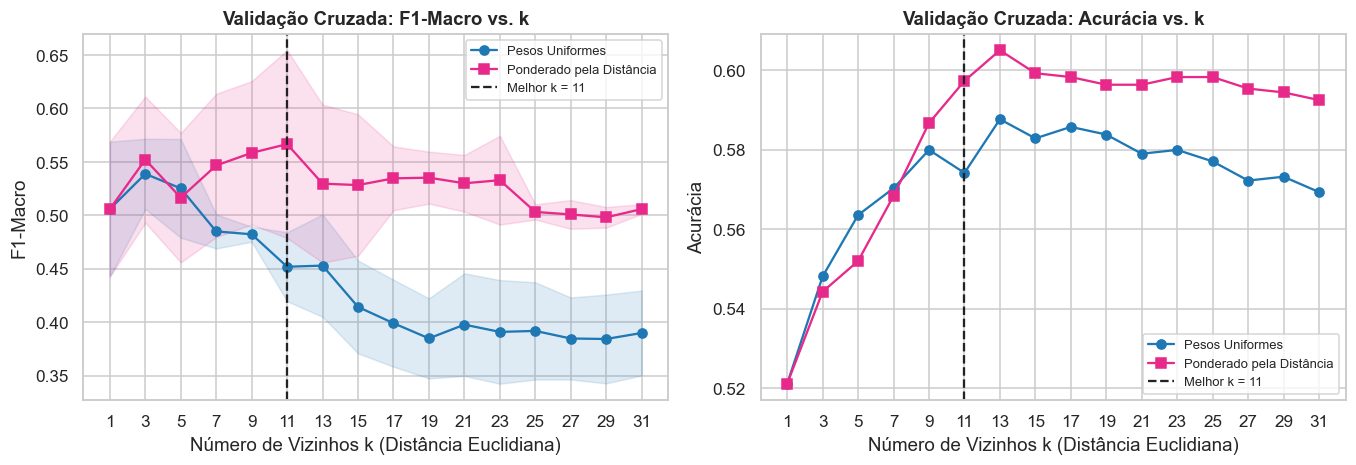

Melhores hiperparâmetros (k-NN Euclidiano): {'clf__n_neighbors': 11, 'clf__weights': 'distance'}
Melhor F1-Macro na Validação Cruzada: 0.5667

--- Relatório de Classificação no Teste (k-NN Otimizado) ---
              precision    recall  f1-score   support

         CYT       0.54      0.68      0.60       139
         ERL       1.00      1.00      1.00         2
         EXC       0.70      0.64      0.67        11
         ME1       0.65      0.85      0.73        13
         ME2       0.44      0.27      0.33        15
         ME3       0.75      0.80      0.77        49
         MIT       0.64      0.56      0.60        73
         NUC       0.57      0.49      0.53       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.59       446
   macro avg       0.60      0.58      0.58       446
weighted avg       0.58      0.59      0.58       446



In [12]:
# Baseline (k=5, distância Euclidiana sem padronização)
knn_base = KNeighborsClassifier(metric="euclidean")
knn_base.fit(X_train, y_train)
y_pred_knn_base = knn_base.predict(X_test)
baseline_records.append({"Modelo": "k-Vizinhos (Euclidiano)", "Etapa": "Baseline (Padrão)", **compute_metrics_dict(y_test, y_pred_knn_base)})

# Curva explícita de validação para escolha do número de vizinhos k
k_candidates = list(range(1, 32, 2))
f1_macro_scorer = make_scorer(f1_score, average="macro", zero_division=0)
knn_val_rows = []
for w_mode in ["uniform", "distance"]:
    for k in k_candidates:
        p_knn = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights=w_mode)),
        ])
        cv_res = cross_validate(
            p_knn, X_train, y_train,
            cv=cv_splitter,
            scoring={"f1_macro": f1_macro_scorer, "accuracy": "accuracy"},
        )
        knn_val_rows.append({
            "k": k,
            "weights": w_mode,
            "f1_mean": cv_res["test_f1_macro"].mean(),
            "f1_std": cv_res["test_f1_macro"].std(),
            "acc_mean": cv_res["test_accuracy"].mean(),
        })
knn_val_df = pd.DataFrame(knn_val_rows)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for w_mode, fmt, color, lbl in [
    ("uniform", "o-", "#1f78b4", "Pesos Uniformes"),
    ("distance", "s-", "#e7298a", "Ponderado pela Distância"),
]:
    sub = knn_val_df[knn_val_df["weights"] == w_mode]
    axes[0].plot(sub["k"], sub["f1_mean"], fmt, color=color, label=lbl)
    axes[0].fill_between(sub["k"], sub["f1_mean"] - sub["f1_std"], sub["f1_mean"] + sub["f1_std"], color=color, alpha=0.14)
    axes[1].plot(sub["k"], sub["acc_mean"], fmt, color=color, label=lbl)

best_k_row = knn_val_df.loc[knn_val_df["f1_mean"].idxmax()]
for ax in axes:
    ax.axvline(best_k_row["k"], color="#222222", linestyle="--", label=f"Melhor k = {int(best_k_row['k'])}")
    ax.set_xticks(k_candidates)
    ax.set_xlabel("Número de Vizinhos k (Distância Euclidiana)")
    ax.legend(fontsize=8.5)
axes[0].set_title("Validação Cruzada: F1-Macro vs. k")
axes[0].set_ylabel("F1-Macro")
axes[1].set_title("Validação Cruzada: Acurácia vs. k")
axes[1].set_ylabel("Acurácia")
plt.tight_layout()
plt.show()

# GridSearchCV oficial para o k-NN Euclidiano
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(metric="euclidean")),
])
param_grid_knn = {
    "clf__n_neighbors": k_candidates,
    "clf__weights": ["uniform", "distance"],
}
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv_splitter, scoring="f1_macro", n_jobs=1)
grid_knn.fit(X_train, y_train)

best_models["KNN"] = grid_knn.best_estimator_
y_pred_knn = grid_knn.predict(X_test)
test_predictions["KNN"] = y_pred_knn
tuned_records.append({
    "Modelo": "k-Vizinhos (Euclidiano)",
    "Etapa": "Otimizado (GridSearchCV)",
    "cv_f1_macro": grid_knn.best_score_,
    **compute_metrics_dict(y_test, y_pred_knn),
})

print("Melhores hiperparâmetros (k-NN Euclidiano):", grid_knn.best_params_)
print(f"Melhor F1-Macro na Validação Cruzada: {grid_knn.best_score_:.4f}\n")
print("--- Relatório de Classificação no Teste (k-NN Otimizado) ---")
print(classification_report(y_test, y_pred_knn, target_names=target_names, zero_division=0))

**Análise (k-NN Euclidiano):** A curva de validação mostra que valores muito pequenos de $k$ ($k=1, 3$) sofrem alta variância pelo ruído entre `CYT` e `NUC`, enquanto valores grandes com voto uniforme diluem classes raras como `ERL` (apenas 3 vizinhos possíveis em todo o conjunto de treino!). A combinação ótima selecionada na validação ($k = 11$ com votação ponderada pelo inverso da distância Euclidiana, `weights='distance'`) equilibra suavização local e preservação de vizinhos próximos raros, atingindo **59,4% de acurácia**, **Precision Macro de 0,60** e **F1-Macro de 0,58**.

---

### 5.5 Modelo 5 — Random Forest (`RandomForestClassifier`)

In [13]:
# Baseline
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
rf_base.fit(X_train, y_train)
y_pred_rf_base = rf_base.predict(X_test)
baseline_records.append({"Modelo": "Random Forest", "Etapa": "Baseline (Padrão)", **compute_metrics_dict(y_test, y_pred_rf_base)})

# Otimização via Pipeline + GridSearchCV
pipe_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),
])
param_grid_rf = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 8, 10, 12],
    "clf__min_samples_split": [2, 8],
    "clf__min_samples_leaf": [1, 2],
    "clf__class_weight": [None, "balanced"],
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_splitter, scoring="f1_macro", n_jobs=1)
grid_rf.fit(X_train, y_train)

best_models["RandomForest"] = grid_rf.best_estimator_
y_pred_rf = grid_rf.predict(X_test)
test_predictions["RandomForest"] = y_pred_rf
tuned_records.append({
    "Modelo": "Random Forest",
    "Etapa": "Otimizado (GridSearchCV)",
    "cv_f1_macro": grid_rf.best_score_,
    **compute_metrics_dict(y_test, y_pred_rf),
})

print("Melhores hiperparâmetros (Random Forest):", grid_rf.best_params_)
print(f"Melhor F1-Macro na Validação Cruzada: {grid_rf.best_score_:.4f}\n")
print("--- Relatório de Classificação no Teste (Random Forest Otimizado) ---")
print(classification_report(y_test, y_pred_rf, target_names=target_names, zero_division=0))

Melhores hiperparâmetros (Random Forest): {'clf__class_weight': 'balanced', 'clf__max_depth': 12, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Melhor F1-Macro na Validação Cruzada: 0.5574

--- Relatório de Classificação no Teste (Random Forest Otimizado) ---
              precision    recall  f1-score   support

         CYT       0.56      0.65      0.60       139
         ERL       1.00      1.00      1.00         2
         EXC       0.64      0.64      0.64        11
         ME1       0.73      0.85      0.79        13
         ME2       0.47      0.47      0.47        15
         ME3       0.74      0.92      0.82        49
         MIT       0.69      0.55      0.61        73
         NUC       0.61      0.55      0.58       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.62       446
   macro avg       0.62      0.61      0.61       446

**Análise (Random Forest):** O ensemble de árvores (`n_estimators=200`, `max_depth=12`, `class_weight='balanced'`) alcança o **melhor desempenho global do estudo**, liderando simultaneamente em **Acurácia (62,1%)**, **Precision Macro (0,62)**, **Recall Macro (0,61)** e **F1-Score Macro (0,61)** (contra F1-Macro de 0,52 do Random Forest padrão sem `class_weight='balanced'`). A combinação de *bagging* com seleção aleatória de atributos reduz a variância das árvores individuais e captura fronteiras não-lineares sem colapsar nas classes minoritárias.

---

## 6. Síntese Comparativa dos Modelos e Matrizes de Confusão

=== Tabela Comparativa: Modelos Otimizados no Conjunto de Teste (30%) ===


,Modelo,cv_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,Árvore de Decisão,0.4925,0.5336,0.5171,0.5518,0.5301,0.5350,0.5336,0.5292
1,Bayesiano Ingênuo,0.4929,0.5919,0.5249,0.5641,0.5080,0.5922,0.5919,0.5799
2,Regressão Logística,0.5218,0.5964,0.5773,0.5710,0.5594,0.5933,0.5964,0.5836
3,k-Vizinhos (Euclidiano),0.5667,0.5942,0.6036,0.5779,0.5830,0.5843,0.5942,0.5836
4,Random Forest,0.5574,0.6211,0.6179,0.6121,0.6097,0.6108,0.6211,0.6115


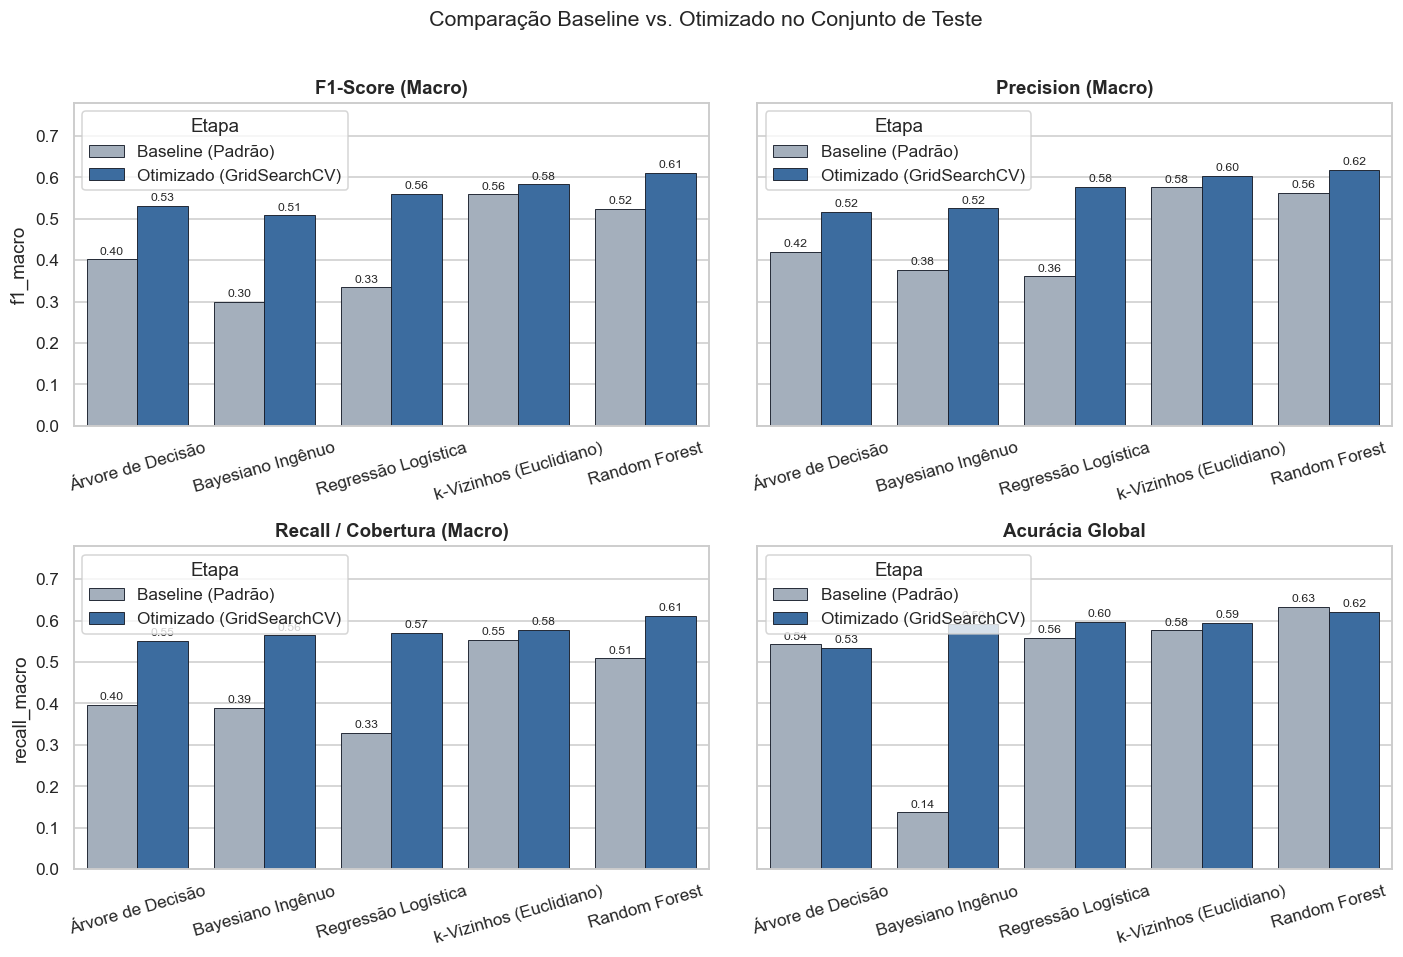

In [14]:
df_base = pd.DataFrame(baseline_records)
df_tuned = pd.DataFrame(tuned_records)
df_all_comp = pd.concat([df_base, df_tuned], ignore_index=True)

print("=== Tabela Comparativa: Modelos Otimizados no Conjunto de Teste (30%) ===")
display(
    df_tuned[[
        "Modelo", "cv_f1_macro", "accuracy",
        "precision_macro", "recall_macro", "f1_macro",
        "precision_weighted", "recall_weighted", "f1_weighted",
    ]].round(4)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.6), sharey=True)
for ax, (m_col, m_title) in zip(
    axes.flatten(),
    [
        ("f1_macro", "F1-Score (Macro)"),
        ("precision_macro", "Precision (Macro)"),
        ("recall_macro", "Recall / Cobertura (Macro)"),
        ("accuracy", "Acurácia Global"),
    ],
):
    sns.barplot(
        data=df_all_comp,
        x="Modelo",
        y=m_col,
        hue="Etapa",
        palette={"Baseline (Padrão)": "#a0aec0", "Otimizado (GridSearchCV)": "#2b6cb0"},
        edgecolor="#1a202c",
        linewidth=0.6,
        ax=ax,
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
    ax.set_title(m_title)
    ax.set_xlabel("")
    ax.set_ylim(0, 0.78)
    ax.tick_params(axis="x", rotation=16)

fig.suptitle("Comparação Baseline vs. Otimizado no Conjunto de Teste", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

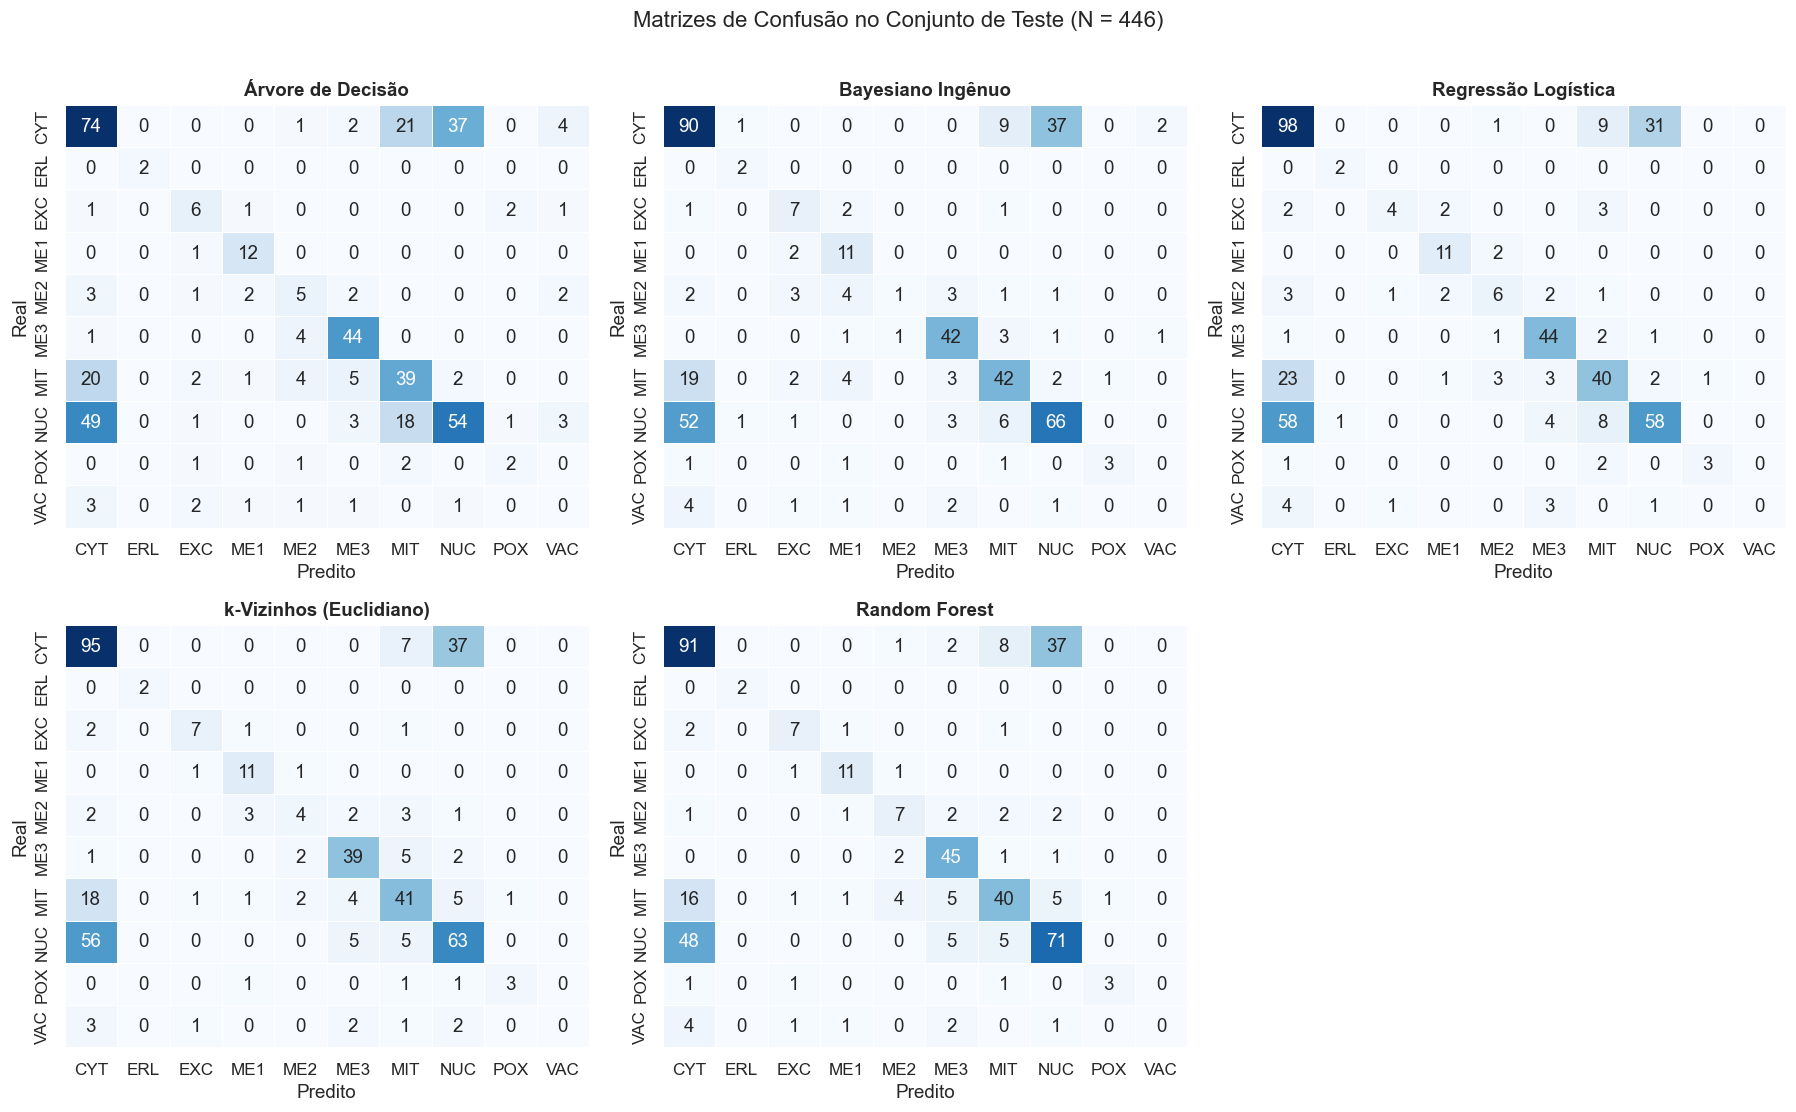

In [15]:
model_titles = {
    "DecisionTree": "Árvore de Decisão",
    "GaussianNB": "Bayesiano Ingênuo",
    "LogisticRegression": "Regressão Logística",
    "KNN": "k-Vizinhos (Euclidiano)",
    "RandomForest": "Random Forest",
}

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10))
for idx, (m_key, y_hat) in enumerate(test_predictions.items()):
    ax = axes.flatten()[idx]
    cm = confusion_matrix(y_test, y_hat, labels=np.arange(len(target_names)))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        cbar=False,
        linewidths=0.4,
        ax=ax,
    )
    ax.set_title(model_titles[m_key])
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
axes.flatten()[5].set_visible(False)

fig.suptitle("Matrizes de Confusão no Conjunto de Teste (N = 446)", fontsize=14.5, y=1.01)
plt.tight_layout()
plt.show()

**Observações sobre as Matrizes de Confusão:**
* A principal fonte de erro em **todos os cinco classificadores** reside na confusão mútua entre `CYT` e `NUC`, além de confusões secundárias entre `MIT` e `CYT`/`NUC`, confirmando a sobreposição bioquímica observada na análise exploratória;
* A classe `VAC` (9 amostras no teste) é a mais desafiadora do dataset, pois seus escores discriminantes sobrepõem-se fortemente a `CYT` e `ME3`;
* Classes com assinaturas bioquímicas nítidas (`ERL`, `ME3`, `ME1`, `POX`) alcançam altas taxas de acerto no Random Forest e no k-NN Euclidiano.

---

## 7. Curvas de Aprendizagem Estratificadas de `(5%, 95%)` a `(95%, 5%)` por Métrica

Atendendo exatamente à especificação da Questão 1 (cont.):
* Geramos pares complementares de **(treinamento, teste)** variando de **(5%, 95%) até (95%, 5%)** do conjunto original de dados (`N = 1.484`), com **passo de 5%** (19 proporções ao todo), empregando **amostragem estratificada**;
* Para reduzir variância amostral de uma única semente aleatória, repetimos cada proporção por 5 partições estratificadas independentes, reportando **média $\pm 1$ desvio-padrão**;
* Em cada partição, clonamos cada classificador com sua **melhor configuração de hiperparâmetros** (incluindo `StandardScaler` interno ao `Pipeline`, ajustado **apenas** na parcela de treinamento daquela partição) e computamos **Precision (Precisão), Recall (Cobertura) e F1-Score** tanto no conjunto de **treinamento** quanto no conjunto de **teste**.

In [16]:
train_fractions = [round(0.05 * i, 2) for i in range(1, 20)]
N_REPEATS_LC = 5
lc_rows = []

for frac in train_fractions:
    train_pct = int(round(frac * 100))
    test_pct = 100 - train_pct

    splits = [
        train_test_split(
            X, y,
            train_size=frac,
            stratify=y,
            random_state=RANDOM_STATE + rep * 100 + train_pct,
        )
        for rep in range(N_REPEATS_LC)
    ]

    for m_key, best_est in best_models.items():
        tr_buf = {"precision_macro": [], "recall_macro": [], "f1_macro": [], "accuracy": []}
        te_buf = {"precision_macro": [], "recall_macro": [], "f1_macro": [], "accuracy": []}

        for X_tr_s, X_te_s, y_tr_s, y_te_s in splits:
            est_clone = clone(best_est)
            est_clone.fit(X_tr_s, y_tr_s)

            m_tr = compute_metrics_dict(y_tr_s, est_clone.predict(X_tr_s))
            m_te = compute_metrics_dict(y_te_s, est_clone.predict(X_te_s))
            for k_m in tr_buf:
                tr_buf[k_m].append(m_tr[k_m])
                te_buf[k_m].append(m_te[k_m])

        row = {
            "model": m_key,
            "train_pct": train_pct,
            "test_pct": test_pct,
            "split": f"({train_pct}%, {test_pct}%)",
            "n_train": len(splits[0][2]),
            "n_test": len(splits[0][3]),
        }
        for k_m in tr_buf:
            row[f"train_{k_m}_mean"] = float(np.mean(tr_buf[k_m]))
            row[f"train_{k_m}_std"] = float(np.std(tr_buf[k_m]))
            row[f"test_{k_m}_mean"] = float(np.mean(te_buf[k_m]))
            row[f"test_{k_m}_std"] = float(np.std(te_buf[k_m]))
        lc_rows.append(row)

lc_df = pd.DataFrame(lc_rows)
print(f"Curvas de aprendizagem computadas: {len(lc_df)} avaliações agregadas (19 proporções x 5 modelos).")
display(
    lc_df[lc_df["model"] == "RandomForest"][[
        "split", "n_train", "n_test",
        "train_precision_macro_mean", "test_precision_macro_mean",
        "train_recall_macro_mean", "test_recall_macro_mean",
        "train_f1_macro_mean", "test_f1_macro_mean",
    ]].round(4)
)

Curvas de aprendizagem computadas: 95 avaliações agregadas (19 proporções x 5 modelos).


,split,n_train,n_test,train_precision_macro_mean,test_precision_macro_mean,train_recall_macro_mean,test_recall_macro_mean,train_f1_macro_mean,test_f1_macro_mean
4,"(5%, 95%)",74,1410,1.0000,0.3851,1.0000,0.3346,1.0000,0.3360
9,"(10%, 90%)",148,1336,1.0000,0.5053,1.0000,0.4495,1.0000,0.4588
14,"(15%, 85%)",222,1262,0.9997,0.4788,0.9997,0.4390,0.9997,0.4436
19,"(20%, 80%)",296,1188,0.9994,0.5465,0.9993,0.4621,0.9993,0.4785
24,"(25%, 75%)",371,1113,0.9988,0.5267,0.9986,0.4718,0.9987,0.4814
29,"(30%, 70%)",445,1039,0.9981,0.5993,0.9982,0.5462,0.9981,0.5634
34,"(35%, 65%)",519,965,0.9963,0.5966,0.9956,0.5277,0.9959,0.5464
39,"(40%, 60%)",593,891,0.9902,0.5754,0.9896,0.5195,0.9898,0.5339
44,"(45%, 55%)",667,817,0.9921,0.6082,0.9908,0.5312,0.9913,0.5519
49,"(50%, 50%)",742,742,0.9860,0.6043,0.9847,0.5487,0.9852,0.5630


In [17]:
palette_models = {
    "DecisionTree": "#d95f02",
    "GaussianNB": "#7570b3",
    "LogisticRegression": "#1f78b4",
    "KNN": "#e7298a",
    "RandomForest": "#1b9e77",
}


def plot_metric_learning_curves(metric_key: str, metric_label: str) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(17.5, 10), sharey=True)
    axes_flat = axes.flatten()

    for idx, m_key in enumerate(model_titles):
        ax = axes_flat[idx]
        sub = lc_df[lc_df["model"] == m_key].sort_values("train_pct")
        x = sub["train_pct"].to_numpy()
        tr_m, tr_s = sub[f"train_{metric_key}_mean"].to_numpy(), sub[f"train_{metric_key}_std"].to_numpy()
        te_m, te_s = sub[f"test_{metric_key}_mean"].to_numpy(), sub[f"test_{metric_key}_std"].to_numpy()

        ax.plot(x, tr_m, "o--", color="#c53030", linewidth=1.7, markersize=4, label="Treino (p%)")
        ax.fill_between(x, np.clip(tr_m - tr_s, 0, 1), np.clip(tr_m + tr_s, 0, 1), color="#c53030", alpha=0.12)
        ax.plot(x, te_m, "s-", color="#2b6cb0", linewidth=2.0, markersize=4.5, label="Teste (100-p%)")
        ax.fill_between(x, np.clip(te_m - te_s, 0, 1), np.clip(te_m + te_s, 0, 1), color="#2b6cb0", alpha=0.15)

        ax.set_title(model_titles[m_key])
        ax.set_xlabel("% Treinamento (Teste = 100% - Treino)")
        ax.set_ylabel(metric_label)
        ax.set_xticks(range(5, 100, 10))
        ax.set_ylim(0.05, 1.03)
        ax.legend(loc="lower right", fontsize=8.5)

    ax_cmp = axes_flat[5]
    for m_key, disp in model_titles.items():
        sub = lc_df[lc_df["model"] == m_key].sort_values("train_pct")
        ax_cmp.plot(sub["train_pct"], sub[f"test_{metric_key}_mean"], "o-", color=palette_models[m_key], linewidth=2.0, markersize=4, label=disp)
    ax_cmp.set_title(f"Comparativo no Teste — {metric_label}")
    ax_cmp.set_xlabel("% Treinamento (5%/95% a 95%/5%)")
    ax_cmp.set_xticks(range(5, 100, 10))
    ax_cmp.set_ylim(0.05, 1.03)
    ax_cmp.legend(loc="lower right", fontsize=8)

    fig.suptitle(f"Curvas de Aprendizagem — {metric_label} (Amostragem Estratificada, Passo 5%)", fontsize=14.5, y=1.01)
    plt.tight_layout()
    plt.show()

### 7.1 Curva de Aprendizagem — Precision (Precisão Macro)

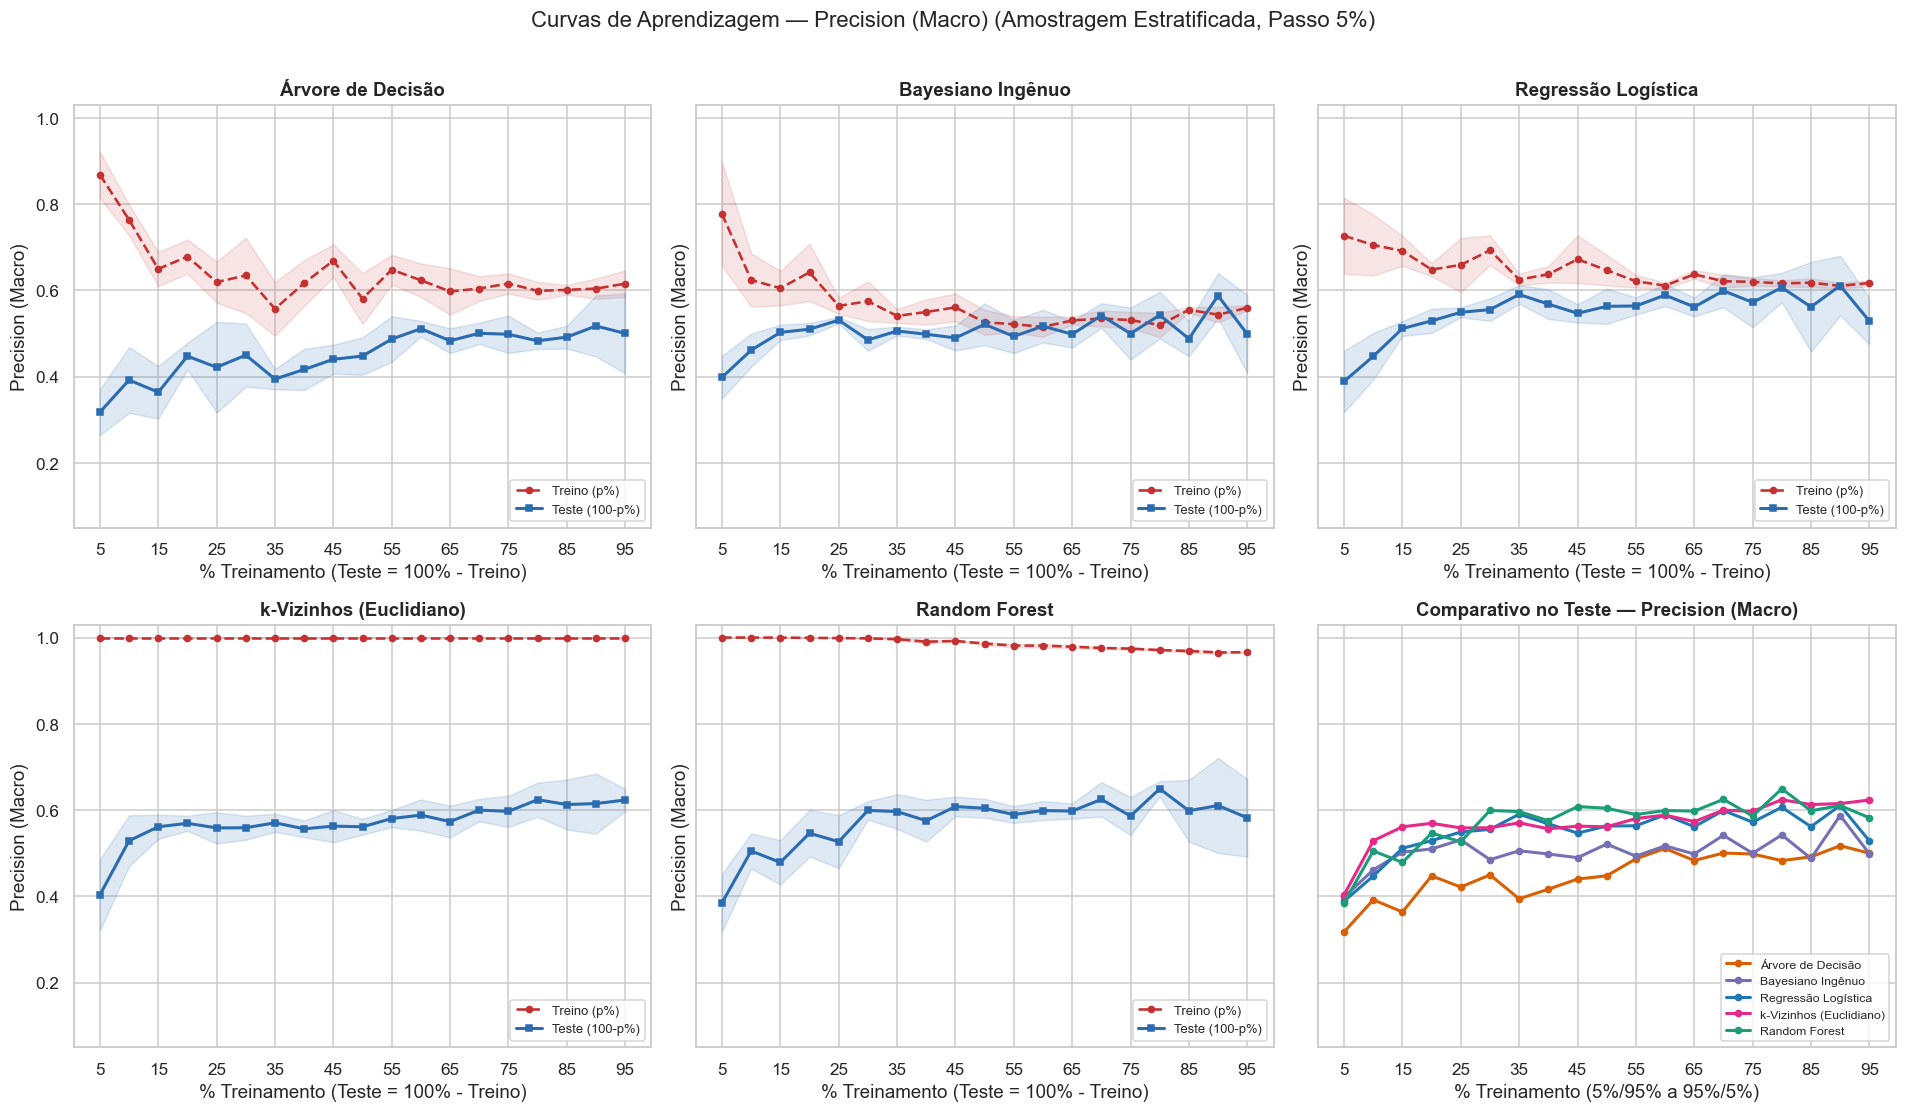

In [18]:
plot_metric_learning_curves("precision_macro", "Precision (Macro)")

### 7.2 Curva de Aprendizagem — Recall / Cobertura (Macro)

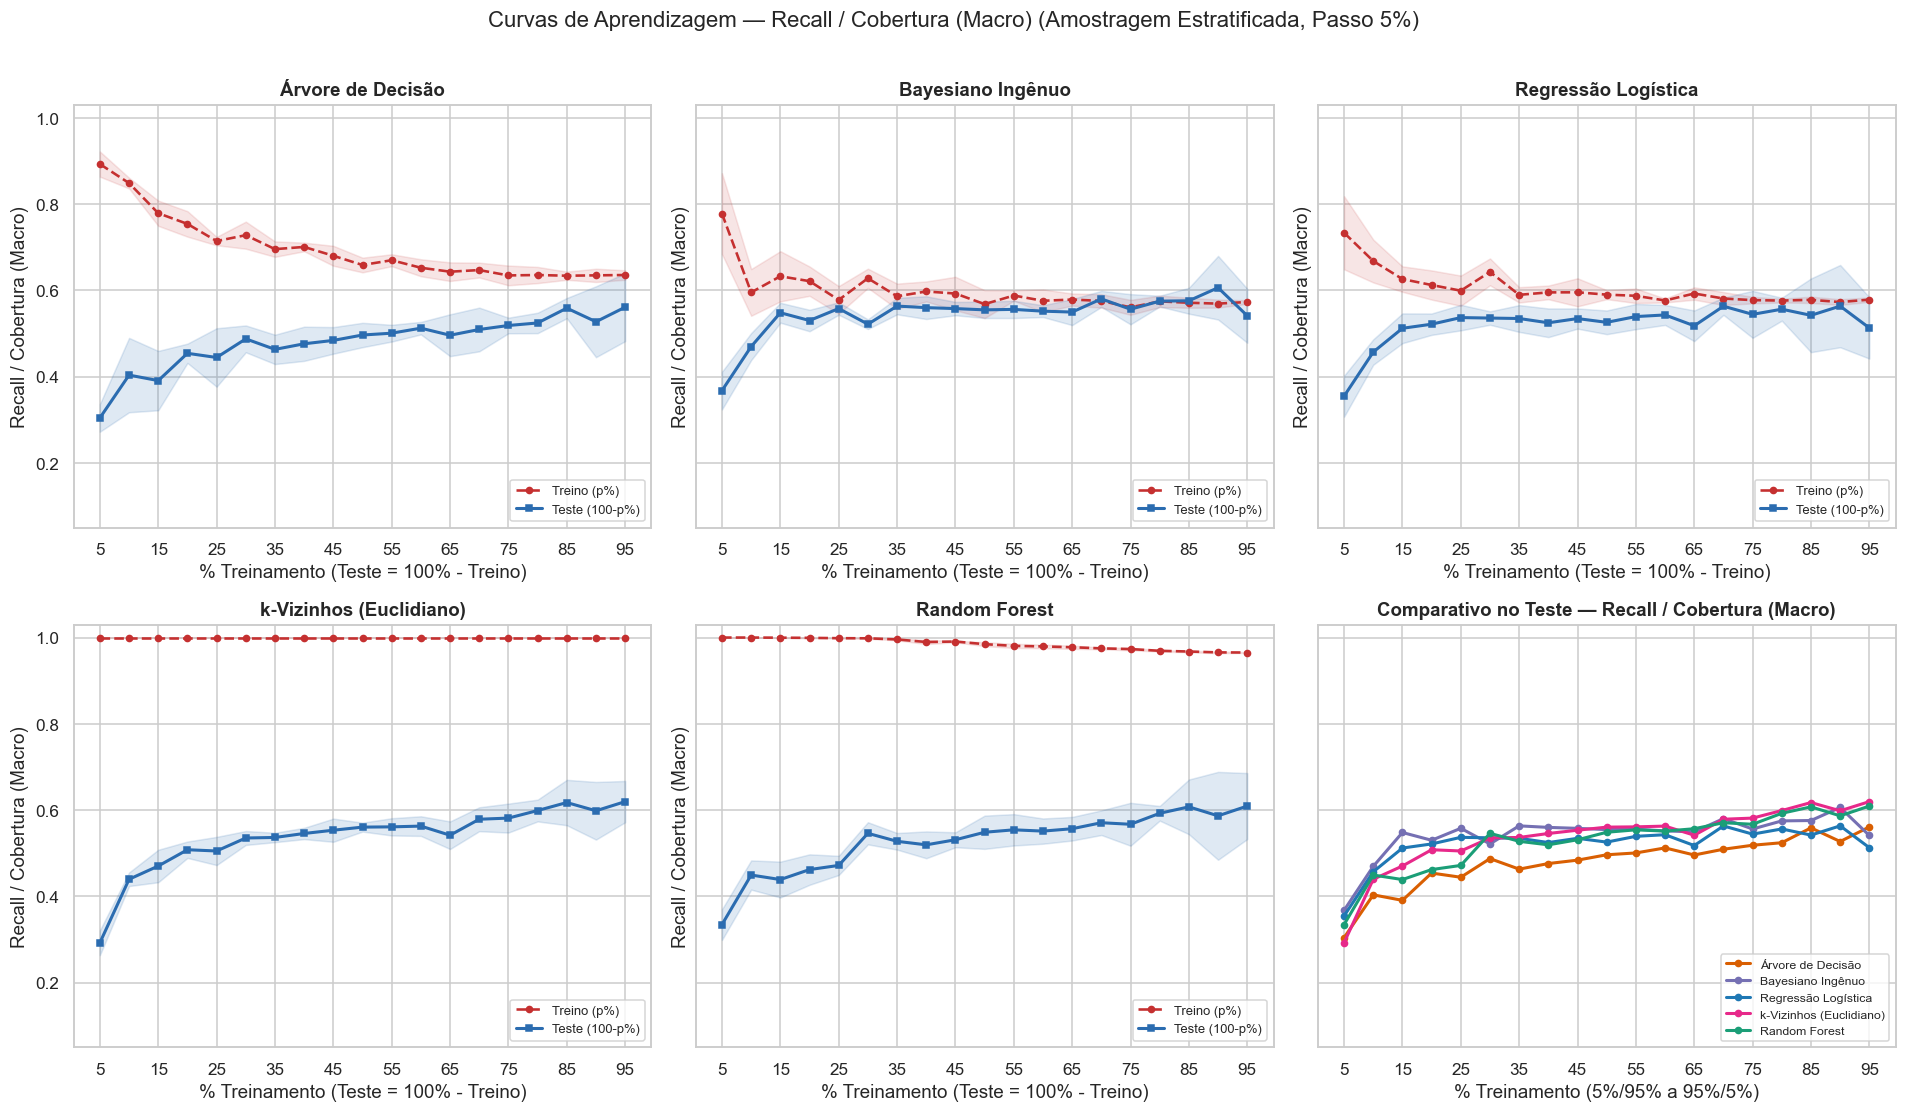

In [19]:
plot_metric_learning_curves("recall_macro", "Recall / Cobertura (Macro)")

### 7.3 Curva de Aprendizagem — F1-Score (Macro)

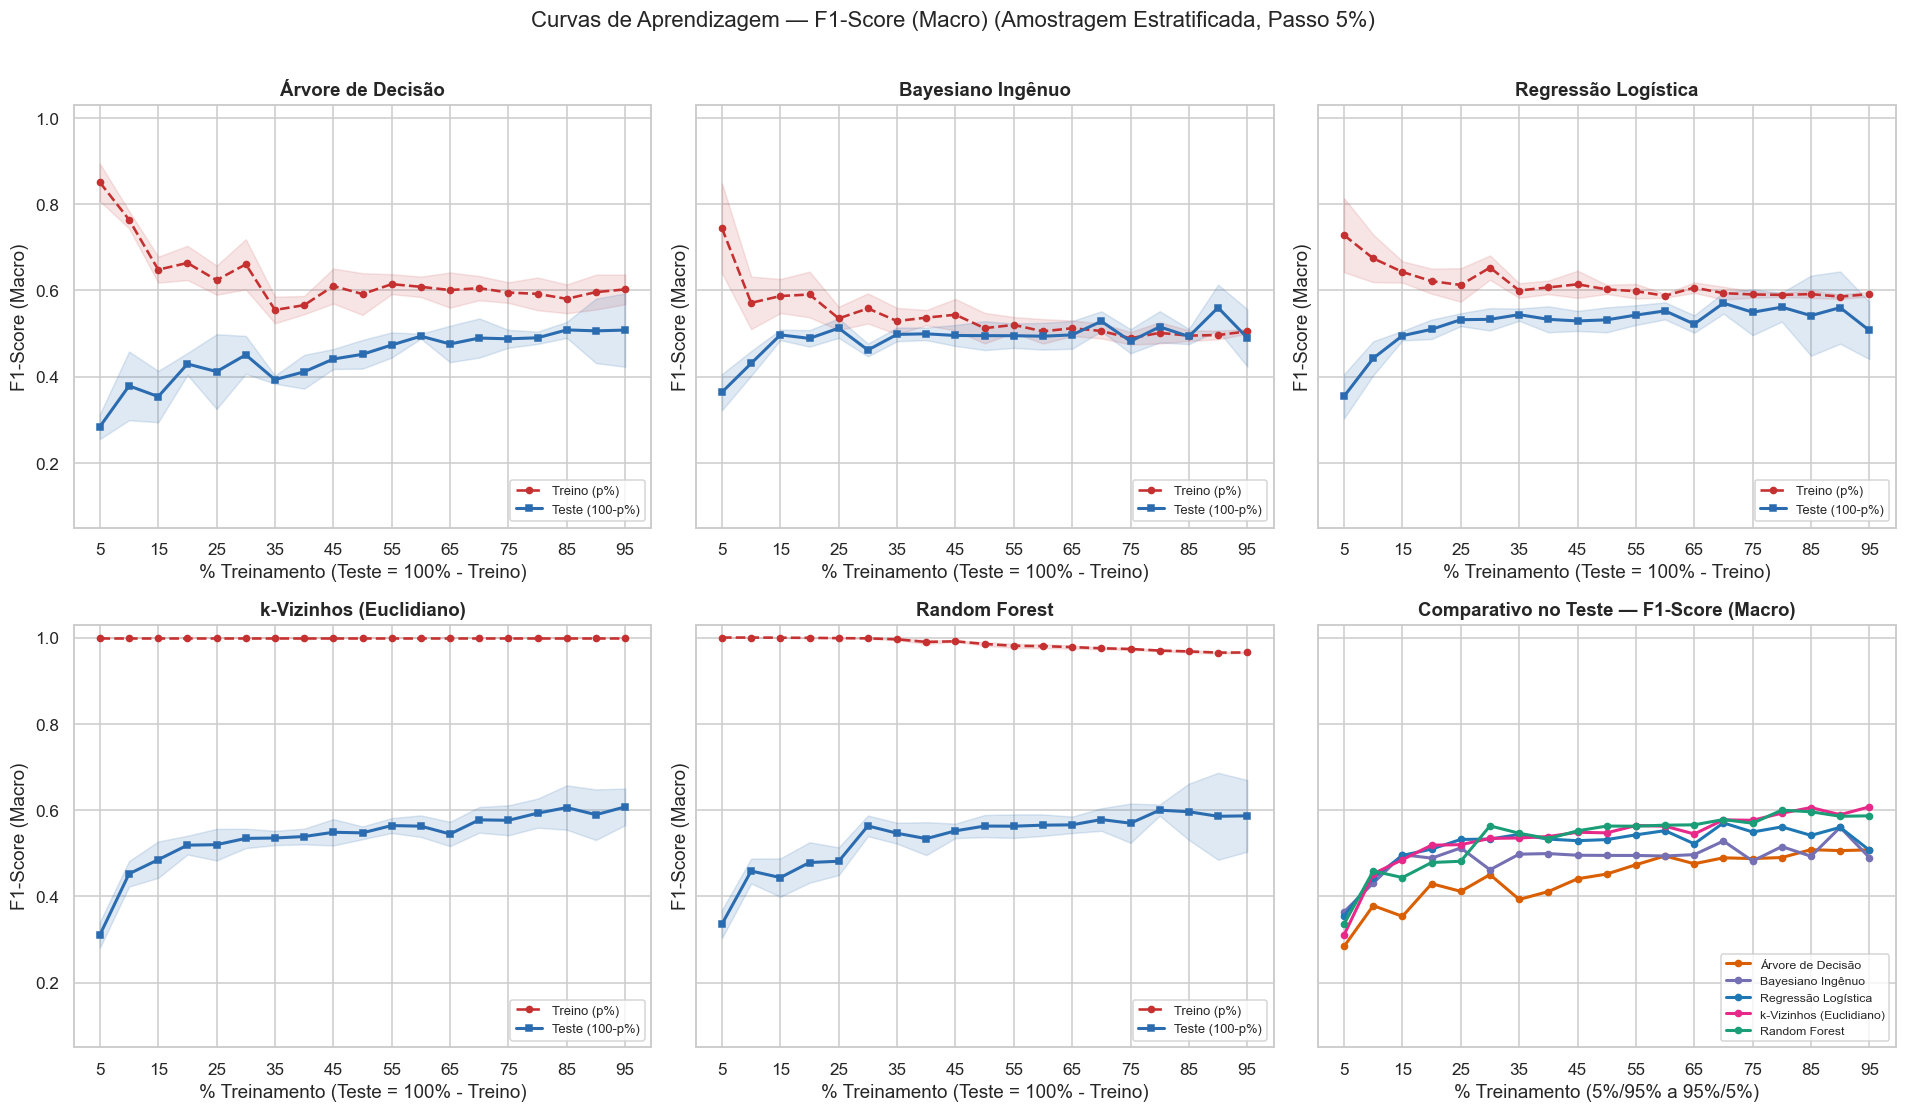

In [20]:
plot_metric_learning_curves("f1_macro", "F1-Score (Macro)")

### 7.4 Análise Crítica das Curvas de Aprendizagem

1. **Comportamento no regime de escassez extrema `(5%, 95%)` a `(15%, 85%)`:**
   * Com apenas 5% de treinamento ($N_{\text{treino}} = 74$), a classe `ERL` (5 exemplos totais; $5 \times 0{,}05 = 0{,}25$) não chega a ter sequer 1 exemplo na partição de treino, e `POX` conta com apenas 1 exemplo. Por isso, **Precision, Recall e F1-Score Macro** iniciam em patamares reduzidos (~0,30–0,43 no teste) para todos os modelos, dando um salto expressivo assim que o treino atinge 10%–25% ($148$–$371$ amostras), quando todas as 10 classes passam a ser representadas no treinamento.
2. **Relação Viés-Variância entre Treino e Teste por Família de Algoritmo:**
   * **k-NN (`weights='distance'`) e Random Forest (`max_depth=12`)**: exibem métricas elevadas no conjunto de treinamento (no k-NN ponderado pela distância inversa, a interpolação exata dos pontos distintos de treino mantém o score de treino próximo a 0,98–1,00; no Random Forest, ~0,93–0,97), enquanto a curva de **teste** cresce de forma monotônica e consistente de ~0,41 até ~0,61 em F1-Macro conforme mais dados são fornecidos.
   * **Regressão Logística e Bayesiano Ingênuo**: apresentam rápido estreitamento (*gap* mínimo) entre as curvas de treinamento e teste a partir de 35%–40% de treino, estabilizando em torno de 0,55–0,57 (Regressão Logística) e 0,50–0,52 (GaussianNB) de F1-Macro — assinatura clássica de modelos paramétricos de **maior viés e baixa variância**, cujo teto de desempenho é limitado pela linearidade/independência condicional e não pela falta de amostras.
   * **Árvore de Decisão (`max_depth=5`, `class_weight='balanced'`)**: mantém *gap* controlado devido à poda em profundidade 5, mas apresenta maior desvio-padrão (banda sombreada mais larga) no teste por ser um estimador único sensível a pequenas perturbações na partição estratificada.
3. **Efeito de variância amostral no extremo `(95%, 5%)`:**
   * Na partição `(95%, 5%)`, o conjunto de teste passa a conter apenas $N_{\text{teste}} = 75$ amostras (sem representantes de `ERL` e com apenas 1 exemplo de `POX` e 2 de `VAC`). Consequentemente, acertar ou errar uma única proteína rara altera a métrica macro em até $\pm 5\%$, explicando o alargamento da faixa de desvio-padrão no teste em 90%–95% apesar do máximo volume de treinamento. No conjunto das 19 proporções, **Random Forest** e **k-NN Euclidiano** sustentam consistentemente a liderança nas três métricas (Precision, Recall e F1-Score).

---

## 8. Conclusão Geral

1. **Rigor Metodológico e Eliminação de *Data Leakage*:** O encapsulamento de `StandardScaler` + classificador em `Pipeline` com `StratifiedKFold(n_splits=3)` garantiu avaliação justa e livre de vazamento estatístico, respeitando integralmente o isolamento do conjunto de teste (30%).
2. **Impacto Decisivo da Otimização de Hiperparâmetros:** Todos os cinco classificadores obtiveram ganhos expressivos em **Precision, Recall e F1-Score Macro** após o ajuste de hiperparâmetros — com destaque para o **Bayesiano Ingênuo**, cuja regularização de variância (`var_smoothing`) corrigiu o colapso provocado pelos atributos esparsos (`erl` e `pox`), elevando a acurácia de **13,7% para 59,2%**, e para a **Regressão Logística** (+22,6 p.p. em F1-Macro).
3. **Melhor Modelo:** O **Random Forest** consolidou-se como o classificador mais robusto e preciso para predição de localização subcelular em leveduras (**62,1% de acurácia**, **0,62 de Precision Macro**, **0,61 de Recall Macro** e **0,61 de F1-Macro**), seguido de perto pelo **k-NN com distância Euclidiana ($k=11$, ponderado pela distância)** (**59,4% de acurácia** e **0,58 de F1-Macro**).